# Lab 09: Nonlinear Representations, Capacity, and Regularization

**Course:** Deep Learning for Computer Vision — 2026  
**Lecture connection:** Lecture 5B

Build a small ReLU network, train it with PyTorch, and inspect how hidden-layer width and regularization affect a nonlinear classification problem.

## 1. Setup

Keep this notebook and `nonlinear_models.py` together. In Google Colab, upload the complete `Lab09` folder before opening the notebook. Run the setup cell again after editing `nonlinear_models.py`.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

candidate_dirs = [
    Path.cwd(),
    Path.cwd() / 'Lab09',
    Path.cwd() / 'DNN' / 'Lab09',
    Path.cwd() / 'Labs' / 'DNN' / 'Lab09',
    Path.cwd() / 'Deep-Learning-for-Computer-Vision' / 'Labs' / 'DNN' / 'Lab09',
]
lab_dir = next((path.resolve() for path in candidate_dirs if (path / 'nonlinear_models.py').is_file()), None)
if lab_dir is None:
    raise FileNotFoundError('Could not find nonlinear_models.py. Keep the Lab09 folder together.')

if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))

import nonlinear_models
importlib.reload(nonlinear_models)

print('Using:', lab_dir / 'nonlinear_models.py')
print('PyTorch:', torch.__version__)

Using: C:\Users\user\Documents\LABS\Deeplearning_in_CV\Lab09\nonlinear_models.py
PyTorch: 2.14.0+cpu


## 2. A nonlinear dataset

The two classes are arranged diagonally. A single straight boundary cannot separate them, so this is a useful example for comparing a linear classifier with a ReLU network.

X shape: (320, 2)
class counts: [160, 160]


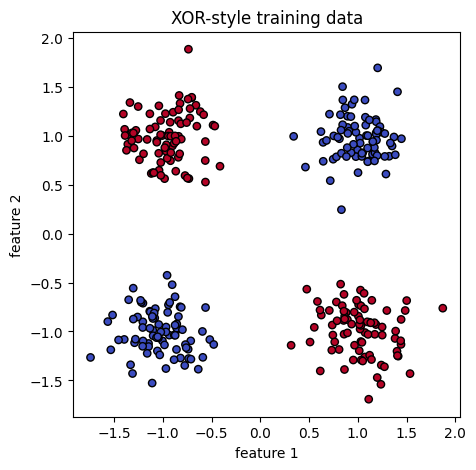

In [2]:
X, y = nonlinear_models.make_xor_dataset()
print('X shape:', tuple(X.shape))
print('class counts:', torch.bincount(y).tolist())

plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='black', s=28)
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.title('XOR-style training data')
plt.axis('equal')
plt.show()

## 3. Exercise 1 — Build a ReLU classifier

Complete `make_two_layer_model` in `nonlinear_models.py`. It must create this sequence:

`Linear(2, hidden width) → ReLU → Linear(hidden width, 2)`

The model returns two class scores for each input point.

In [3]:
importlib.reload(nonlinear_models)

torch.manual_seed(0)
model = nonlinear_models.make_two_layer_model(hidden_width=6)
print(model)

assert isinstance(model, nn.Sequential)
assert len(model) == 3
assert isinstance(model[0], nn.Linear)
assert isinstance(model[1], nn.ReLU)
assert isinstance(model[2], nn.Linear)
assert model[0].in_features == 2
assert model[0].out_features == 6
assert model[2].in_features == 6
assert model[2].out_features == 2
assert model(X[:5]).shape == (5, 2)
print('Model-structure check passed.')

Sequential(
  (0): Linear(in_features=2, out_features=6, bias=True)
  (1): ReLU()
  (2): Linear(in_features=6, out_features=2, bias=True)
)
Model-structure check passed.


## 4. Exercise 2 — One PyTorch training step

Complete `train_step` in `nonlinear_models.py`. Follow the same order used in the lecture: compute scores, compute cross-entropy loss, clear old gradients, call `backward`, then update the parameters. PyTorch handles the gradient computation; manual backpropagation is not part of this lab.

In [4]:
importlib.reload(nonlinear_models)

torch.manual_seed(3)
model = nonlinear_models.make_two_layer_model(hidden_width=8)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
initial_loss = F.cross_entropy(model(X), y).item()
loss_history = nonlinear_models.train_for_steps(model, X, y, optimizer, steps=300)
final_accuracy = nonlinear_models.accuracy(model, X, y)

print(f'initial loss: {initial_loss:.4f}')
print(f'final loss:   {loss_history[-1]:.4f}')
print(f'train accuracy: {final_accuracy:.1%}')

assert loss_history[-1] < initial_loss
assert final_accuracy >= 0.95
print('Training-step check passed.')

initial loss: 0.7027
final loss:   0.0383
train accuracy: 100.0%
Training-step check passed.


## 5. Capacity

A linear classifier has no hidden ReLU representation. The models below use different hidden widths. Compare their decision regions and their training accuracies.

linear          loss=0.6929  accuracy=49.7%
1 ReLU unit     loss=0.6931  accuracy=50.0%
4 ReLU units    loss=0.0328  accuracy=100.0%
16 ReLU units   loss=0.0140  accuracy=100.0%


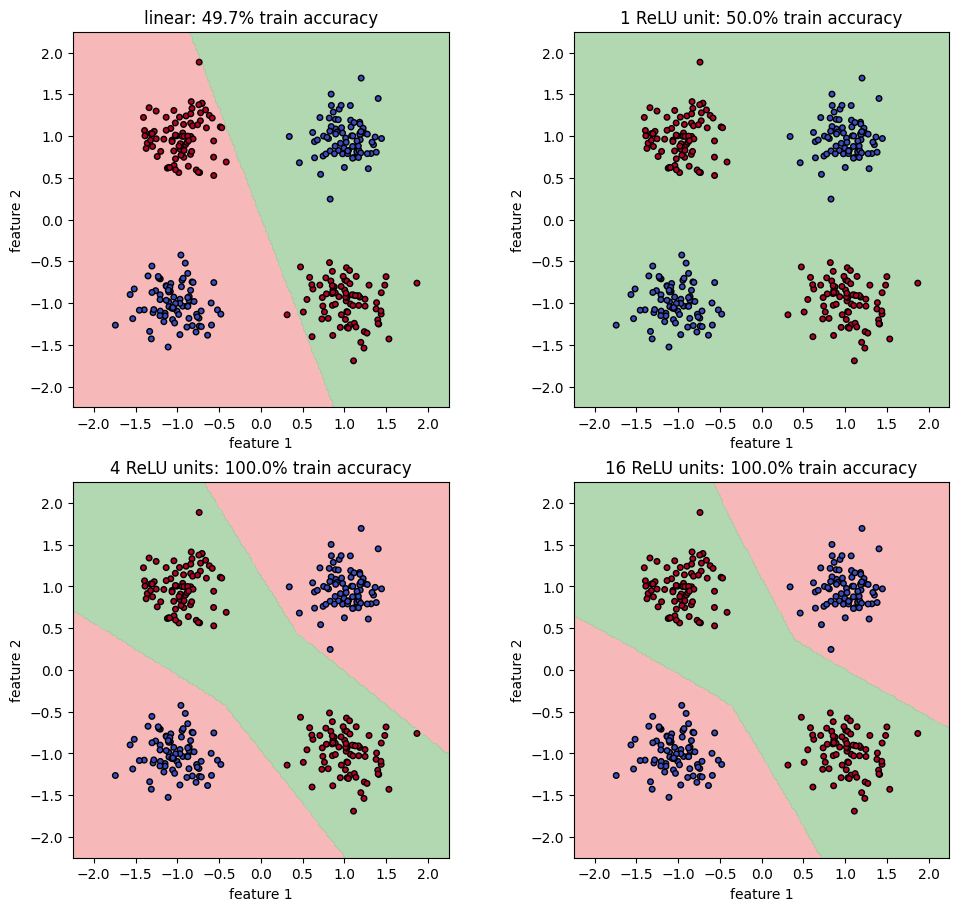

In [5]:
def fit_model(model, *, learning_rate=0.1, weight_decay=0.0, steps=500):
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay,
    )
    losses = nonlinear_models.train_for_steps(model, X, y, optimizer, steps)
    return losses, nonlinear_models.accuracy(model, X, y)


def draw_region(ax, model, title):
    grid_x, grid_y, grid_predictions = nonlinear_models.prediction_grid(model)
    ax.contourf(
        grid_x.numpy(),
        grid_y.numpy(),
        grid_predictions.numpy(),
        levels=[-0.5, 0.5, 1.5],
        colors=['#f4a6a6', '#9fcf9f'],
        alpha=0.8,
    )
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='black', s=16)
    ax.set_title(title)
    ax.set_xlabel('feature 1')
    ax.set_ylabel('feature 2')
    ax.set_aspect('equal')


models = {}
torch.manual_seed(10)
models['linear'] = nn.Linear(2, 2)
for width in [1, 4, 16]:
    torch.manual_seed(10)
    models[f'{width} ReLU unit' + ('s' if width != 1 else '')] = nonlinear_models.make_two_layer_model(width)

fig, axes = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)
for ax, (name, candidate) in zip(axes.ravel(), models.items()):
    losses, candidate_accuracy = fit_model(candidate)
    draw_region(ax, candidate, f'{name}: {candidate_accuracy:.1%} train accuracy')
    print(f'{name:14s}  loss={losses[-1]:.4f}  accuracy={candidate_accuracy:.1%}')
plt.show()

## 6. Regularization

Weight decay is the optimizer form of L2 regularization. It discourages large weights. Compare the reported parameter norms as the regularization strength changes.

weight_decay=0        loss=0.0098  accuracy=100.0%  parameter L2 norm=5.457
weight_decay=0.0001   loss=0.0099  accuracy=100.0%  parameter L2 norm=5.442
weight_decay=0.1      loss=0.2804  accuracy=100.0%  parameter L2 norm=2.314


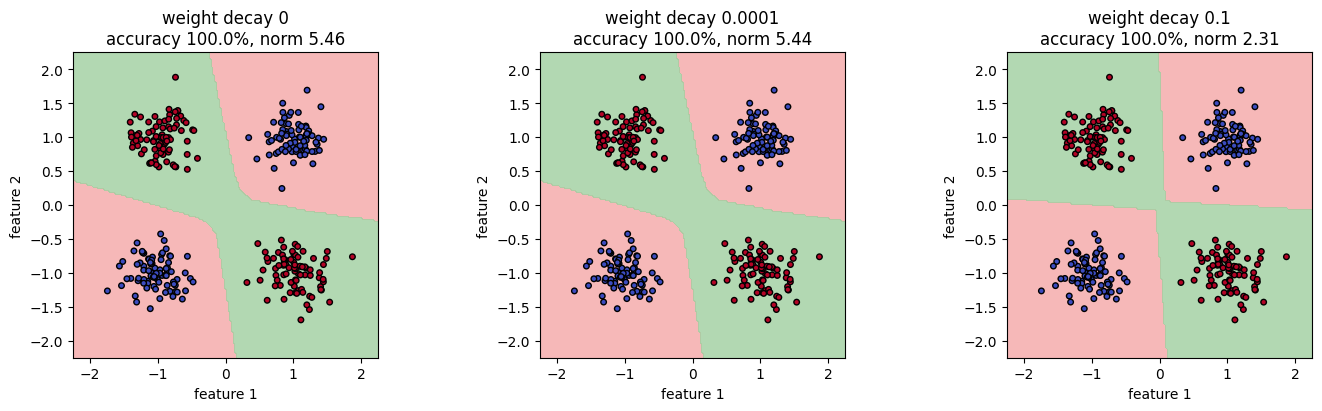

In [6]:
weight_decays = [0.0, 1e-4, 1e-1]
results = {}

for weight_decay in weight_decays:
    torch.manual_seed(21)
    candidate = nonlinear_models.make_two_layer_model(hidden_width=16)
    losses, candidate_accuracy = fit_model(
        candidate,
        learning_rate=0.1,
        weight_decay=weight_decay,
        steps=500,
    )
    parameter_norm = nonlinear_models.parameter_l2_norm(candidate.parameters())
    results[weight_decay] = (candidate, candidate_accuracy, parameter_norm)
    print(
        f'weight_decay={weight_decay:<7g}  '
        f'loss={losses[-1]:.4f}  '
        f'accuracy={candidate_accuracy:.1%}  '
        f'parameter L2 norm={parameter_norm:.3f}'
    )

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (weight_decay, (candidate, candidate_accuracy, parameter_norm)) in zip(axes, results.items()):
    draw_region(
        ax,
        candidate,
        f'weight decay {weight_decay:g}\naccuracy {candidate_accuracy:.1%}, norm {parameter_norm:.2f}',
    )
plt.show()

## 7. Questions

Answer briefly in new Markdown cells.

1. Why does the linear classifier struggle on this dataset?
2. What changes in the decision region when the ReLU hidden width increases?
3. What does increasing weight decay do to the parameter L2 norm in this experiment?
4. Why must `optimizer.zero_grad()` come before `loss.backward()` in the training step?

1. Why does the linear classifier struggle on this dataset?

The linear classifier struggles because the XOR-style dataset is not linearly separable. The two classes occupy diagonally opposite regions, so a single straight decision boundary cannot correctly separate them. A nonlinear model with a ReLU activation can learn more complex decision boundaries.

2. What changes in the decision region when the ReLU hidden width increases?

Increasing the ReLU hidden width gives the network more neurons to learn different features and construct more complex decision boundaries. Consequently, the model can represent more flexible decision regions and potentially classify the dataset more accurately.

3. What does increasing weight decay do to the parameter L2 norm in this experiment?

Increasing weight decay generally reduces the parameter L2 norm because it penalizes large weights during optimization. This encourages smaller parameter values and helps control model complexity, although excessive weight decay can reduce classification accuracy.

4. Why must optimizer.zero_grad() come before loss.backward() in the training step?

PyTorch accumulates gradients by default rather than automatically replacing them. Therefore, optimizer.zero_grad() clears gradients from the previous iteration before loss.backward() calculates new gradients. Without clearing them, gradients would accumulate across training steps, potentially resulting in incorrect parameter updates.

